<a href="https://colab.research.google.com/github/AGSCL/repr2026/blob/main/ejemplo_google_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ejemplo de compendio en RStudio, Posit Cloud y Google Colab (Windows, Mac y Linux)

- Se crea en la carpeta actual. En RStudio: abrir antes un proyecto.

- Solo caracteres ASCII: sin tildes para evitar mojibake

- A continuación, usted podrá ejecutar un guión/*script* para generar una carpeta reproducible de un proyecto en R.

- **Guarde una copia de este proyecto en Drive**.


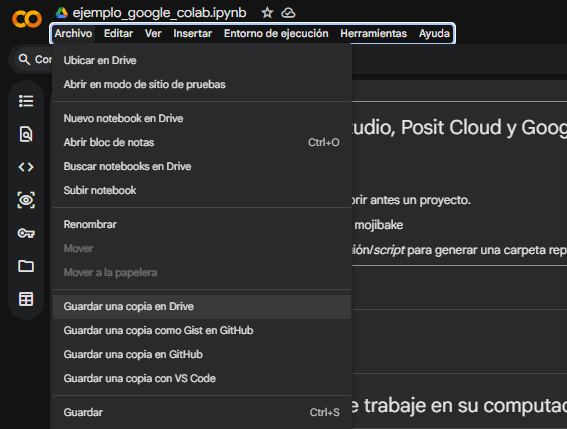

In [ ]:
#@title ⚠️ Confirmación Inicial { display-mode: "form" }

ya_hice_una_copia = FALSE #@param {type:"boolean"}

if (!ya_hice_una_copia) {
  cat("❌ Error: Por favor, ve a Archivo > Guardar una copia en Drive antes de continuar.\n")
  invisible(NULL) # para no mostrar los detalles del error
} else {
  message("¡Perfecto! Puedes continuar con el proyecto.")
}

In [ ]:
#@title # 0. Limpiar sesión (en caso que trabaje en su computador) { display-mode: "form" }
rm(list = ls())   # list: objetos a borrar (todos)
graphics.off()    # cerrar graficos abiertos
cat("\014")       # limpiar consola

In [ ]:
#@title # 1. DATOS DEL PROYECTO (editar solo aqui) { display-mode: "form" }
nombre   <- "Nombre"                       # nombre de quien crea el proyecto
apellido <- "Apellido"                     # apellido
correo   <- "nombre.apellido@correo.com"   # correo de contacto
fecha    <- "2026-10-03"                   # AAAA-MM-DD: fija la version de TODOS los paquetes
paquetes <- c("data.tree", "here")         # paquetes que usara el proyecto
carpetas <- c("_data",      # datos
              "_outputs",   # resultados, tablas y modelos
              "_doc",       # informes y manuscritos
              "_figures",   # graficos
              "_lib",       # funciones de apoyo
              "_hist",      # versiones anteriores
              "_lit")       # literatura

In [ ]:
#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:
#
#@title # 2. VERIFICAR QUE ESTAMOS EN UN PROYECTO { display-mode: "form" }
if (Sys.getenv("RSTUDIO") == "1" && length(Sys.glob("*.Rproj")) == 0) {   # RStudio sin archivo .Rproj
  stop("No estas en un proyecto de RStudio. ",
       "Crea uno con File > New Project y corre este script dentro de el.")
}
proyecto <- basename(getwd())        # nombre del proyecto = nombre de su carpeta
message("Proyecto en: ", getwd())    # en Colab: usar setwd() antes si quieres otra carpeta

In [ ]:
#@title # 3. REPOSITORIO CON FECHA FIJA (todos instalan las mismas versiones) { display-mode: "form" }
options(
  repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/", fecha)),  # Posit Package Manager en esa fecha
  renv.consent = TRUE                                                         # renv no pide permiso la primera vez
)

In [ ]:
#@title # 4. SUBCARPETAS { display-mode: "form" }
for (d in carpetas) dir.create(path = d, showWarnings = FALSE)   # crear cada carpeta (si ya existe, no avisa)
invisible(file.create(file.path(carpetas, ".gitkeep")))          # git no guarda carpetas vacias
invisible(file.create(".here"))                                  # marca la raiz para here::here() (sirve en Colab)

In [ ]:
#@title 5. DESCRIPTION: AUTORIA Y PAQUETES { display-mode: "form" }
writeLines(
  text = c(
    paste("Title:", proyecto),
    sprintf('Authors@R: person("%s", "%s", email = "%s", role = c("aut", "cre"))',
            nombre, apellido, correo),
    paste("Imports:", paste(paquetes, collapse = ", "))
  ),
  con = "DESCRIPTION"               # archivo de salida
)

In [ ]:
#@title # 6. RENV: LIBRERIA DEL PROYECTO (aislada del sistema) { display-mode: "form" }
if (!requireNamespace("renv", quietly = TRUE)) install.packages("renv")
renv::init(
  bare = TRUE,                                  # no buscar ni instalar paquetes todavia
  settings = list(snapshot.type = "implicit"),  # renv.lock con lo que usan los scripts y el DESCRIPTION
  restart = FALSE                               # no reiniciar R (necesario en Colab)
)
renv::install(
  packages = paquetes,                          # paquetes a instalar (en Linux baja binarios)
  prompt = FALSE                                # no pedir confirmacion
)
renv::snapshot(prompt = FALSE)                  # escribir versiones exactas en renv.lock
renv::isolate()                                 # copiar paquetes dentro del proyecto (autocontenido)

In [ ]:
#@title # 7. README CON ARBOL DEL PROYECTO { display-mode: "form" }

invisible(file.create("README.md"))         # crear antes para que aparezca en el arbol
rutas <- list.files(
  path = ".",                               # desde la raiz del proyecto
  recursive = TRUE,                         # incluir subcarpetas
  include.dirs = TRUE                       # mostrar carpetas vacias
)
rutas <- rutas[!startsWith(rutas, "renv/")] # no listar los paquetes instalados
nodo  <- data.tree::as.Node(data.frame(pathString = file.path(proyecto, rutas)))
arbol <- data.tree::ToDataFrameTree(nodo)$levelName
arbol <- gsub(paste0(intToUtf8(166), "|<U[+]00A6>"), "|", arbol)   # simbolo de rama -> |
arbol <- gsub(paste0(intToUtf8(176), "|<U[+]00B0>"), "`", arbol)   # simbolo de ultima rama -> `
arbol <- trimws(arbol, which = "right")                            # quitar espacios al final
writeLines(
  text = c(
    paste("#", proyecto), "",
    "## Descripcion", "Objetivo del analisis.", "",
    "## Requisitos",
    paste("- R", getRversion()),
    paste("- Paquetes:", paste(paquetes, collapse = ", "), "(versiones en renv.lock)"),
    "- Detalle del entorno: `_doc/entorno.txt`", "",
    "## Ejecucion",
    "1. Abrir la carpeta del proyecto (o el archivo .Rproj).",
    "2. Correr `renv::restore()` para instalar las mismas versiones.", "",
    "## Estructura", "```text", arbol, "```"
  ),
  con = "README.md"                         # archivo de salida
)
cat(readLines("README.md"), sep = "\n")     # mostrar resultado

 ## 8. REPORTE DEL ENTORNO (R base + here; sirve al final de cualquier analisis)

In [ ]:
#@title Reporte del entorno { display-mode: "form" }

sincronizado <- renv::status()$synchronized              # TRUE = lo instalado coincide con renv.lock
entorno <- data.frame(
  dato  = c("Proyecto", "Fecha", "R", "Sistema operativo", "Plataforma",
            "Codificacion UTF-8", "renv.lock al dia"),
  valor = c(here::here(),                               # ubicacion del proyecto
            format(Sys.time(), "%Y-%m-%d %H:%M %Z"),    # cuando se corrio (con zona horaria)
            R.version.string,                           # version de R
            utils::osVersion,                           # Windows, macOS o Linux, con su version
            R.version$platform,                         # arquitectura: define que binarios se instalan
            l10n_info()[["UTF-8"]],                     # FALSE = riesgo de mojibake
            sincronizado)
)
pk <- sort(loadedNamespaces())                          # paquetes usados en esta sesion
paquetes_sesion <- data.frame(
  paquete  = pk,
  version  = vapply(pk, getNamespaceVersion, ""),       # version cargada
  origen   = vapply(pk, function(p) {                  # CRAN o RSPM, github, base (viene con R) o local
    d <- utils::packageDescription(p)
    c(d$Repository, d$RemoteType, d$Priority, "local")[1]
  }, ""),
  libreria = vapply(pk, function(p) dirname(find.package(p)), "")  # de donde se cargo (renv/library = aislado)
)

pk
paquetes_sesion

Para reproducir en otro computador: abrir el proyecto y correr `renv::restore()`